<a href="https://colab.research.google.com/github/aranzatorres546-hash/M-TODOS-NUM-RICOS-/blob/main/interpolacion_neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método de Neville


**Curso:** Metodos Numericos ·

 **Alumno:** Aranza Citlali Rivero Torres ·
  
**Fecha:** 19 de noviembre de 2026

---



Se quiere **aproximar $f(1.5)$** con el polinomio de interpolación, pero **sin construir el polinomio completo**: interesa su *valor* en un punto $\bar{x}$, no sus coeficientes. Datos de la tabla 3.10:

| $i$ | 0 | 1 | 2 | 3 | 4 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $x_i$ | 1.0 | 1.3 | 1.6 | 1.9 | 2.2 |
| $f(x_i)$ | 0.7651977 | 0.6200860 | 0.4554022 | 0.2818186 | 0.1103623 |



**Teorema.** Sean $x_i \ne x_j$ dos nodos y sean $P_{\hat{j}}$ y $P_{\hat{i}}$ los polinomios de interpolación en todos los nodos *menos* $x_j$ y *menos* $x_i$, respectivamente. Entonces

$$P(x) = \frac{(x - x_j)\,P_{\hat{j}}(x) - (x - x_i)\,P_{\hat{i}}(x)}{x_i - x_j}$$

interpola en **todos** los nodos. *(Comprobación: en $x_i$ se anula el segundo término y queda $f(x_i)$; análogo en $x_j$; en los demás nodos ambos polinomios valen $f$ y el cociente también.)*

**Algoritmo.** Sea $Q_{i,j}$ el valor en $\bar{x}$ del polinomio de grado $j$ que usa los nodos $x_{i-j},\dots,x_i$. Entonces $Q_{i,0} = f(x_i)$ y

$$Q_{i,j} = \frac{(\bar{x} - x_{i-j})\,Q_{i,j-1} - (\bar{x} - x_i)\,Q_{i-1,j-1}}{x_i - x_{i-j}}, \qquad i=1,\dots,n,\ j=1,\dots,i$$

La diagonal $Q_{i,i}$ usa los primeros $i+1$ nodos; $Q_{n,n}$ es la aproximación con todos. Si $|Q_{i,i} - Q_{i-1,i-1}|$ es menor que una tolerancia, se puede parar antes.

**Frente a Newton.** Neville devuelve solo el valor en un punto (hay que repetirlo para otro $\bar{x}$); Newton calcula una vez los coeficientes y sirve para muchos puntos. Costo de Neville: $O(n^2)$.

In [2]:
# NOTA: librerías que usamos
#   math       -> funciones matemáticas (aquí, factorial)
#   numpy      -> arreglos y operaciones numéricas
#   matplotlib -> la gráfica final
import math
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# NOTA: los datos van en listas de Python; se acceden con corchetes, por ejemplo x_datos[0].
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]                                    # nodos x_0, ..., x_4
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]      # f(x_i), tabla 3.10
x_evaluar = 1.5                                                        # punto donde queremos aproximar f

# NOTA: len() cuenta los elementos; si hay n+1 nodos el grado máximo es n.
n = len(x_datos) - 1
print("Nodos:", n + 1, "  Grado máximo:", n, "  Evaluamos en x =", x_evaluar)

Nodos: 5   Grado máximo: 4   Evaluamos en x = 1.5


In [1]:
def interpolacion_neville(x_vals, y_vals, x_eval):
    """Algoritmo 3.1 (Neville). Devuelve la matriz Q con Q[i][j] = P_{i-j,...,i}(x_eval)."""
    n = len(x_vals) - 1

    # NOTA: así se crea una matriz como lista de listas (comprensión de listas).
    # '_' es una variable que no usamos. Cada fila es una lista distinta de n+1 ceros.
    Q = [[0.0 for _ in range(n + 1)] for _ in range(n + 1)]

    # ENTRADA: la primera columna son los valores de f.
    for i in range(n + 1):
        Q[i][0] = y_vals[i]

    # NOTA: range(1, n + 1) da 1, 2, ..., n (el último número no se incluye).
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            # Fórmula del algoritmo, partida en tres pasos para leerla mejor:
            term1 = (x_eval - x_vals[i - j]) * Q[i][j - 1]
            term2 = (x_eval - x_vals[i]) * Q[i - 1][j - 1]
            denominador = x_vals[i] - x_vals[i - j]
            Q[i][j] = (term1 - term2) / denominador

    return Q

In [5]:
def imprimir_tabla(Q):
    """Imprime la parte triangular de Q (las entradas con j <= i)."""
    # NOTA: fila[:i + 1] es una "rebanada": los primeros i+1 elementos de la fila.
    # Se usa esto en vez de descartar los ceros para no esconder un valor que sea 0 de verdad.
    print(f"{'x_i':>5}" + "".join(f"{'Q_i,'+str(j):>12}" for j in range(len(Q))))
    for i, fila in enumerate(Q):
        print(f"{x_datos[i]:>5.1f}" + "".join(f"{v:>12.7f}" for v in fila[:i + 1]))


Se ejecuta el algoritmo con $\bar{x} = 1.5$. La columna $j$ contiene las aproximaciones de grado $j$.

In [7]:
Q = interpolacion_neville(x_datos, y_datos, x_evaluar)
imprimir_tabla(Q)

  x_i       Q_i,0       Q_i,1       Q_i,2       Q_i,3       Q_i,4
  1.0   0.7651977
  1.3   0.6200860   0.5233449
  1.6   0.4554022   0.5102968   0.5124715
  1.9   0.2818186   0.5132634   0.5112857   0.5118127
  2.2   0.1103623   0.5104270   0.5137361   0.5118302   0.5118200


##  Verificación


In [ ]:
# NOTA: un diccionario {clave: valor} guarda pares. Aquí la clave es (i, j) y el valor
# es lo que da el libro para Q[i][j]. .items() recorre los pares.
esperados = {(1, 1): 0.5233449, (2, 1): 0.5102968, (2, 2): 0.5124715, (4, 4): 0.5118200}
for (i, j), ref in esperados.items():
    ok = abs(Q[i][j] - ref) < 5e-8          # coinciden a los 7 decimales del libro
    print(f"Q[{i}][{j}] = {Q[i][j]:.7f}   libro: {ref:.7f}   {'OK' if ok else 'NO COINCIDE'}")

Q[1][1] = 0.5233449   libro: 0.5233449   OK
Q[2][1] = 0.5102968   libro: 0.5102968   OK
Q[2][2] = 0.5124715   libro: 0.5124715   OK
Q[4][4] = 0.5118200   libro: 0.5118200   OK



Se compara cada $Q_{i,i}$ con el valor exacto $J_0(1.5)$.

In [8]:
# NOTA: la diagonal Q[i][i] es la aproximación que usa los primeros i+1 nodos.
diag = [Q[i][i] for i in range(n + 1)]

# NOTA: los datos son valores de la función de Bessel J0(x). Su serie de potencias es
#   J0(x) = suma_k (-1)^k (x^2/4)^k / (k!)^2
# y nos da un valor de referencia ("exacto") en x = 1.5.
def J0(t, terminos=30):
    return sum((-1)**k * (t * t / 4)**k / math.factorial(k)**2 for k in range(terminos))

# Antes de confiar en la serie, comprobamos que reproduce la tabla (diferencia ~1e-8 por redondeo).
print("Máx |J0(x_i) - f(x_i)| en los nodos:", max(abs(J0(xi) - yi) for xi, yi in zip(x_datos, y_datos)))

exacto = J0(x_evaluar)
print(f"\nValor exacto f({x_evaluar}) = {exacto:.7f}\n")

# La última columna es |Q_ii - Q_(i-1)(i-1)|: es lo que usa el criterio de paro del algoritmo.
print(f"{'grado':>6}{'Q[i][i]':>14}{'|error|':>12}{'|Q_ii - Q_(i-1)(i-1)|':>24}")
for i, q in enumerate(diag):
    paso = abs(q - diag[i - 1]) if i > 0 else float("nan")
    print(f"{i:>6}{q:>14.7f}{abs(q - exacto):>12.2e}{paso:>24.2e}")

Máx |J0(x_i) - f(x_i)| en los nodos: 4.062561448359148e-08

Valor exacto f(1.5) = 0.5118277

 grado       Q[i][i]     |error|   |Q_ii - Q_(i-1)(i-1)|
     0     0.7651977    2.53e-01                     nan
     1     0.5233449    1.15e-02                2.42e-01
     2     0.5124715    6.44e-04                1.09e-02
     3     0.5118127    1.50e-05                6.59e-04
     4     0.5118200    7.68e-06                7.30e-06



Por unicidad $Q_{4,4}$ debe coincidir con el valor del polinomio de grado 4 que obtiene otro método.

In [9]:
# NOTA: el polinomio de grado 4 que pasa por 5 puntos es ÚNICO, así que su valor en 1.5
# debe coincidir con el de np.polyfit (que usa otro método). np.polyval evalúa el polinomio.
P4_en_x = np.polyval(np.polyfit(x_datos, y_datos, 4), x_evaluar)
print(f"Q[4][4]            = {Q[4][4]:.10f}")
print(f"np.polyfit grado 4 = {P4_en_x:.10f}")
print(f"Diferencia         = {abs(Q[4][4] - P4_en_x):.2e}")

Q[4][4]            = 0.5118199942
np.polyfit grado 4 = 0.5118199942
Diferencia         = 5.55e-16



Grafucamente cada punto rojo es la aproximación con un grado más; la línea azul es el valor exacto.

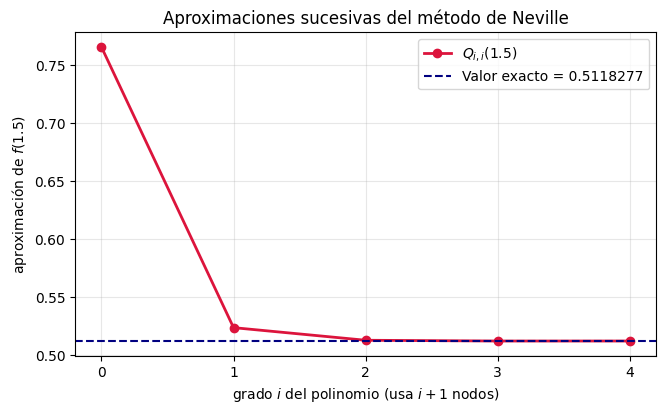

In [10]:
grados = list(range(n + 1))

plt.figure(figsize=(7.5, 4.2))
plt.plot(grados, diag, "o-", color="crimson", lw=2, label=r"$Q_{i,i}(1.5)$")     # aproximaciones
plt.axhline(exacto, color="navy", ls="--", label=f"Valor exacto = {exacto:.7f}")  # referencia
plt.xticks(grados)
plt.xlabel("grado $i$ del polinomio (usa $i+1$ nodos)")
plt.ylabel("aproximación de $f(1.5)$")
plt.title("Aproximaciones sucesivas del método de Neville")
plt.grid(alpha=0.3); plt.legend()
plt.show()

## Usando SymPy

La función de Neville solo usa sumas, restas, productos y divisiones, así que **funciona igual si en lugar de $\bar{x} = 1.5$ le pasamos una variable simbólica $x$**. Entonces cada $Q_{i,j}$ sale como un polinomio en $x$ y $Q_{4,4}(x)$ es el polinomio de interpolación completo. Se usa para dos cosas: (1) ver el polinomio desarrollado y (2) comprobar que, evaluado en $1.5$, da el mismo valor que el cálculo numérico.



In [11]:
# NOTA: SymPy hace álgebra simbólica (fórmulas exactas, no solo números).
# Truco: la MISMA función de Neville sirve si en lugar de un número le pasamos una
# variable simbólica x. Como la función solo suma, resta, multiplica y divide, cada Q[i][j]
# sale como un polinomio en x, y Q[4][4] es el polinomio de interpolación de grado 4.
import sympy as sp
sp.init_printing()                   # Jupyter mostrará las fórmulas en LaTeX

X = sp.symbols("x")                  # variable simbólica

# NOTA: sp.Rational("1.3") guarda 1.3 como la fracción exacta 13/10 (sin error de redondeo).
nodos_sym   = [sp.Rational(str(v)) for v in x_datos]
valores_sym = [sp.Rational(str(v)) for v in y_datos]

Q_sym = interpolacion_neville(nodos_sym, valores_sym, X)   # <- la misma función de arriba

# Q[1][1] es la recta que pasa por los dos primeros puntos. sp.expand desarrolla los productos.
display(sp.expand(Q_sym[1][1]))

# Q[4][4] es P_4(x); lo desarrollamos en potencias de x.
P_sym = sp.expand(Q_sym[4][4])
P_sym

37467101   1451117⋅x
──────── - ─────────
30000000    3000000 

     4           3            2                         
887⋅x    268723⋅x    1111471⋅x    7133639⋅x   1187948093
────── + ───────── - ────────── + ───────── + ──────────
486000    4860000     3240000     97200000    1215000000

In [12]:
# NOTA: sp.Poly(...).all_coeffs() devuelve los coeficientes de MAYOR a menor grado,
# el mismo orden que usa np.polyfit, así que se pueden comparar directamente.
coef_sympy = [float(c) for c in sp.Poly(P_sym, X).all_coeffs()]
coef_polyfit = np.polyfit(x_datos, y_datos, 4)
print("Coeficientes (SymPy)  :", np.round(coef_sympy, 7))
print("Coeficientes (polyfit):", np.round(coef_polyfit, 7))
print("¿Coinciden?", np.allclose(coef_sympy, coef_polyfit, atol=1e-8))

# NOTA: .subs(variable, valor) sustituye la variable simbólica por un número.
valor_sym = float(P_sym.subs(X, x_evaluar))
print(f"P_4(1.5) con SymPy = {valor_sym:.7f}    Q[4][4] numérico = {Q[4][4]:.7f}")
print("Diferencia:", abs(valor_sym - Q[4][4]))

Coeficientes (SymPy)  : [ 0.0018251  0.0552928 -0.3430466  0.0733913  0.9777351]
Coeficientes (polyfit): [ 0.0018251  0.0552928 -0.3430466  0.0733913  0.9777351]
¿Coinciden? True
P_4(1.5) con SymPy = 0.5118200    Q[4][4] numérico = 0.5118200
Diferencia: 1.1102230246251565e-16




> ### Resultado
>
> $$\boxed{f(1.5) \approx Q_{4,4}(1.5) = 0.5118200}$$
>
> Valor exacto: $f(1.5) = 0.5118277$  ·  Error absoluto: $7.7\times 10^{-6}$
>
> Polinomio de interpolación asociado (forma desarrollada):
>
> $$P_4(x) = 0.0018251x^4 +0.0552928x^3 -0.3430466x^2 +0.0733913x +0.9777351$$

**Conclusión.** El método de Neville genera aproximaciones de grado creciente a $f(1.5)$ sin construir el polinomio. Las entradas coinciden con las del libro, $Q_{4,4}$ coincide con el polinomio de grado 4 obtenido por otro método, y la diferencia entre aproximaciones consecutivas se reduce al subir el grado.